# Thí nghiệm bổ sung phân đoạn polyp

**Deep Learning · Nhóm 06 · Kvasir-SEG**

Notebook tái lập mục **3.1.7** và **4.2.5** trong [báo cáo Word](../reports/BaoCao_DeepLearning_Nhom_06.docx). Phần đầu sàng lọc ảnh tương tự giữa train, validation và test. Phần sau cắt tỉa U-Net++ có giám sát sâu và đo từng nhánh bằng checkpoint C đã khóa.

1. Chuẩn bị môi trường và tải checkpoint theo [README](../README.md).
2. Chọn kernel Python của môi trường vừa cài và chọn **Restart Kernel → Run All**. Mặc định notebook chạy lại cả hai phép thử. Chuyển `RUN_EXPERIMENTS` thành `False` để đọc minh chứng đã lưu.
3. Kết quả mới nằm trong thư mục riêng dưới `results/`. Bảng 4.7 trong Word dùng số đo tham chiếu đã lưu. Thời gian của lượt mới có thể khác tùy thiết bị và tải hệ thống.

In [1]:
from contextlib import redirect_stdout
from datetime import datetime, timezone
from io import StringIO
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

RUN_EXPERIMENTS = True
DEVICE = "auto"  # "cuda" cho GPU NVIDIA hoặc "cpu" cho CPU

current = Path.cwd().resolve()
root = next(
    (path for path in (current, *current.parents) if (path / "configs/protocol_lock.json").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Mở notebook từ thư mục repo hoặc thư mục notebooks/.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

reference = root / "results/report_figures/extension_20261123"
timestamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
run = root / "results" / f"notebook_supplement_{timestamp}" if RUN_EXPERIMENTS else reference
print("Chế độ:", "Chạy lại" if RUN_EXPERIMENTS else "Đọc kết quả báo cáo")
if RUN_EXPERIMENTS:
    print("Thư mục lượt chạy:", run.relative_to(root).as_posix())

Chế độ: Chạy lại
Thư mục lượt chạy: results/notebook_supplement_20261123_025552_771899


## 1 Sàng lọc ảnh tương tự giữa các tập

Mỗi ảnh được chuyển sang xám và thu về 32×32. Biến đổi cosin rời rạc (DCT) cho phép lấy 63 hệ số tần số thấp sau khi bỏ hệ số DC. Ta ghi một bit cho mỗi hệ số tùy theo nó có lớn hơn trung vị hay không. Số bit khác nhau giữa hai mã là khoảng cách Hamming.

Code chỉ xét hai ảnh thuộc hai tập khác nhau. Khoảng cách tối đa **6/63 bit** dùng để chọn cặp xem lại. Xem [mã sàng lọc](../scripts/audit_split_similarity.py) và [tài liệu về pHash dùng DCT](https://www.phash.org/docs/pubs/thesis_zauner.pdf).

In [2]:
from scripts.audit_split_similarity import audit

if RUN_EXPERIMENTS:
    print("Đang đọc manifest, tính pHash và so các cặp khác tập…")
    with redirect_stdout(StringIO()):
        audit(run / "similarity")

similarity_dir = run / "similarity"
similarity = json.loads((similarity_dir / "similarity_summary.json").read_text(encoding="utf-8"))
candidates = pd.read_csv(similarity_dir / "similarity_candidates.csv")
split_names = {"test/train": "Train–test", "train/val": "Train–validation", "test/val": "Validation–test"}
counts = pd.DataFrame([
    {
        "Hai tập": split_names[key],
        "Số cặp đã so": similarity["screened_by_split"][key],
        "Số cặp đạt ngưỡng": similarity["candidates_by_split"].get(key, 0),
    }
    for key in split_names
])
assert counts["Số cặp đã so"].sum() == similarity["pairs_screened"]
assert counts["Số cặp đạt ngưỡng"].sum() == len(candidates)
display(counts)

Đang đọc manifest, tính pHash và so các cặp khác tập…


,Hai tập,Số cặp đã so,Số cặp đạt ngưỡng
0,Train–test,105000,8
1,Train–validation,105000,9
2,Validation–test,22500,0


Ảnh cạnh nhau giúp kiểm tra các cặp có cùng bố cục hay cùng vùng polyp. pHash có thể đánh dấu hai ảnh khác nhau vì chúng có cấu trúc sáng tối tương tự. Thiếu mã bệnh nhân và video nên các cặp dưới đây chỉ được gọi là ứng viên tương tự.

,ID ảnh bên trái,ID ảnh bên phải,Hai tập,Khoảng cách Hamming
0,cju13cgqmnhwn0988yrainhcp,cju8c1a0ws7o208181c6lbsom,test/train,4
1,cju5w7xn0lrkq0801f9k0htgx,cju7aifyo1p3n07552nxjx51f,test/train,4
2,cju0t4oil7vzk099370nun5h9,cju7cp6dw244p0818gncdol4m,train/val,6
3,cju13cgqmnhwn0988yrainhcp,cju83kxitjv340987z09m0ezy,test/train,6
4,cju160wshltz10993i1gmqxbe,cju5thdbrjp1108715xdfx356,train/val,6


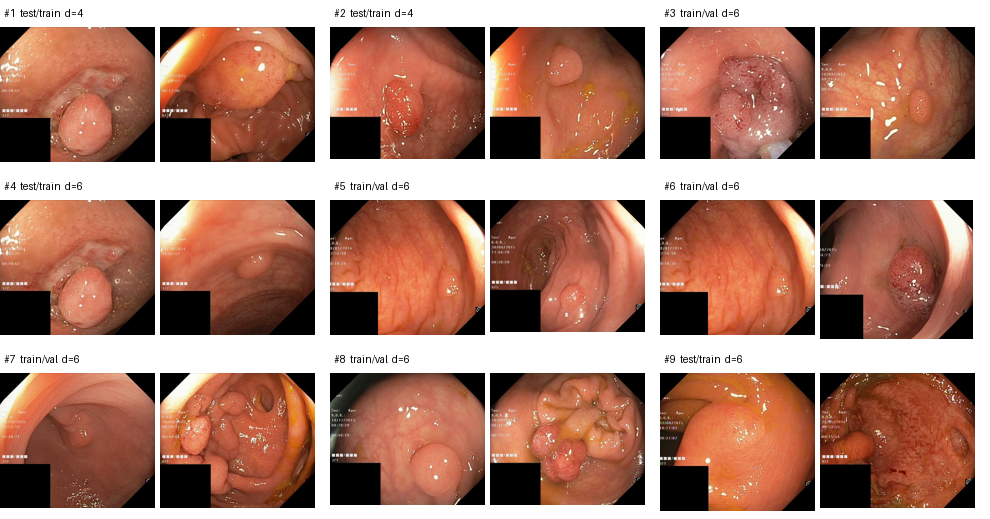

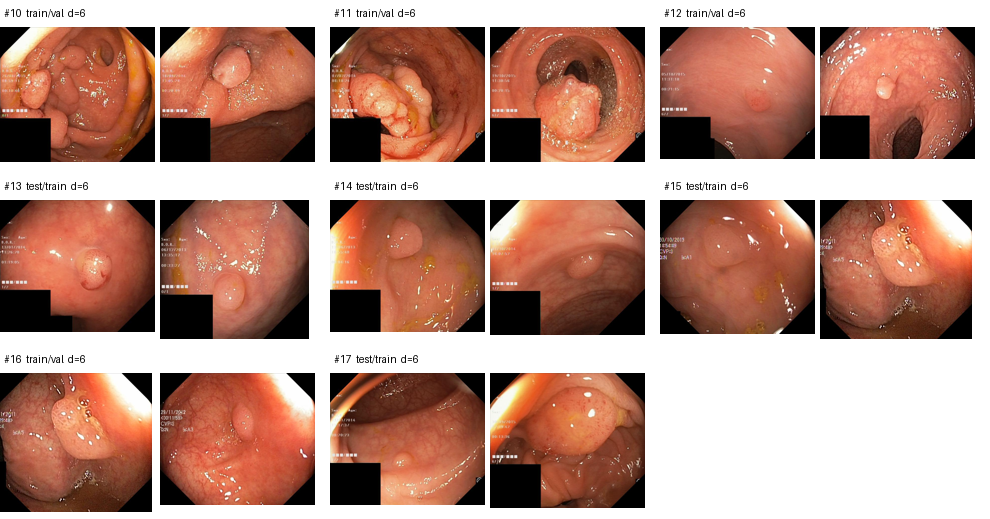

In [3]:
display(candidates.head().rename(columns={
    "left_id": "ID ảnh bên trái", "right_id": "ID ảnh bên phải",
    "split_pair": "Hai tập", "hamming_distance": "Khoảng cách Hamming",
}))
for sheet in sorted(similarity_dir.glob("candidates_*.png")):
    display(Image(filename=str(sheet), width=900))

## 2 Kiểm tra độ nhạy của thứ hạng Dice

Lấy các ID ảnh test xuất hiện ở ít nhất một cặp ứng viên. Tạm bỏ chúng khỏi bảng dự đoán đã lưu, sau đó lấy Dice trung bình trên phần test còn lại. Kết quả chính của báo cáo vẫn dùng đủ 150 ảnh test.

In [4]:
sensitivity = pd.read_csv(similarity_dir / "similarity_sensitivity.csv").set_index("model")
before = sensitivity["reference_dice"].sort_values(ascending=False).index.tolist()
after = sensitivity["retained_dice"].sort_values(ascending=False).index.tolist()
display(sensitivity.rename(columns={
    "flagged_test_images": "Ảnh tạm loại", "retained_test_images": "Ảnh còn lại",
    "reference_dice": "Dice test đầy đủ", "retained_dice": "Dice test còn lại",
}).round(4))
print("Thứ hạng trước:", " > ".join(before))
print("Thứ hạng sau:  ", " > ".join(after))

,Ảnh tạm loại,Ảnh còn lại,Dice test đầy đủ,Dice test còn lại
model,,,,
A,6,144,0.6014,0.6039
B,6,144,0.6682,0.6705
C,6,144,0.7390,0.7386


Thứ hạng trước: C > B > A
Thứ hạng sau:   C > B > A


## 3 Cắt tỉa U-Net++ theo head

Head thứ `L` lấy đầu ra của node `X(0,L)`. Để tính node đó, lớp `PrunedHead` chỉ giữ các node thỏa `i + j ≤ L` và head đã chọn. Ví dụ, L1 chỉ dùng `X(0,0)`, `X(1,0)` và `X(0,1)`. L4 giữ đủ 15 node nhưng chỉ gọi head cuối. Các nhánh dùng chung trọng số đã học từ checkpoint C, không huấn luyện lại.

[Mã mạng con và benchmark](../scripts/benchmark_pruned_heads.py) kiểm tra đầu ra của mỗi nhánh với head tương ứng trong forward đầy đủ. Sau đó script đo FP32 trên batch 8 đã nằm sẵn trên thiết bị. Mỗi nhánh được khởi động 10 lần trước 5 lượt đo, mỗi lượt 12 lần forward. Cách đo chỉ bao gồm forward. Ý tưởng chọn head nông khi suy luận được trình bày trong [bài U-Net++](https://arxiv.org/abs/1807.10165).

In [5]:
from scripts.benchmark_pruned_heads import benchmark

if RUN_EXPERIMENTS:
    print("Đang chạy các nhánh trên validation, test và đo thời gian forward…")
    with redirect_stdout(StringIO()):
        benchmark(run / "pruning", requested_device=DEVICE, repeats=5)

pruning_dir = run / "pruning"
measurement = json.loads((pruning_dir / "pruning_summary.json").read_text(encoding="utf-8"))
pruning = pd.read_csv(pruning_dir / "pruning_summary.csv").set_index("level")
per_image = pd.read_csv(pruning_dir / "pruning_per_image.csv")
assert measurement["manifest_sha256"] == similarity["manifest_sha256"]
assert not per_image.duplicated(["split", "image_id", "level"]).any()
assert (per_image.groupby(["split", "level"]).size() == 150).all()
assert set(per_image["split"]) == {"val", "test"} and set(per_image["level"]) == {1, 2, 3, 4}
assert np.allclose(pruning["dice_test"], per_image.query("split == 'test'").groupby("level")["dice"].mean())
print("Thiết bị:", measurement["device"])
print("SHA-256 checkpoint C:", measurement["checkpoint_sha256"])

Đang chạy các nhánh trên validation, test và đo thời gian forward…


Thiết bị: NVIDIA GeForce RTX 5060 Laptop GPU
SHA-256 checkpoint C: e292d3cf7dbe09d94377279ff839389c3c3824ef87a345a382376da42eeb8eca


In [6]:
columns = {
    "nodes": "Số node", "parameters": "Số tham số",
    "dice_val": "Dice validation", "dice_test": "Dice test",
    "median_ms_per_image": "Forward (ms/ảnh)",
    "max_abs_logit_delta": "Sai khác logit tối đa",
    "mask_pixel_mismatches": "Số pixel khác",
}
assert pruning["max_abs_logit_delta"].max() <= 1e-5
assert pruning["mask_pixel_mismatches"].sum() == 0
display(pruning[list(columns)].rename(columns=columns).rename_axis("Nhánh L").round(4))

,Số node,Số tham số,Dice validation,Dice test,Forward (ms/ảnh),Sai khác logit tối đa,Số pixel khác
Nhánh L,,,,,,,
1,3,101537,0.3676,0.3328,2.8401,0.0,0
2,6,511681,0.5862,0.5606,6.1159,0.0,0
3,10,2205537,0.7676,0.7268,10.6041,0.0,0
4,15,9042177,0.7888,0.7390,16.5644,0.0,0


## 4 Đọc đánh đổi giữa Dice và tốc độ

Biểu đồ dùng **lượt tham chiếu của Bảng 4.7** để đối chiếu đúng số trong Word. Bảng trên là kết quả của lượt notebook đang đọc hoặc đang chạy. So thời gian L3 và L4 trong cùng một lượt đo. Chênh lệch Dice là số điểm phần trăm tính trên thang Dice từ 0 tới 1.

Bảng 4.7: L3 giảm 36.6% thời gian forward, Dice test giảm 1.22 điểm phần trăm.


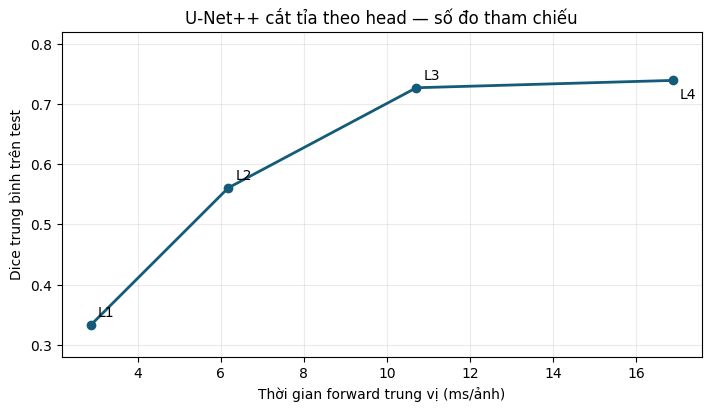

In [7]:
report = pd.read_csv(reference / "pruning/pruning_summary.csv").set_index("level")
l3, l4 = report.loc[3], report.loc[4]
time_reduction = 100 * (1 - l3["median_ms_per_image"] / l4["median_ms_per_image"])
dice_drop = 100 * (l4["dice_test"] - l3["dice_test"])
print(f"Bảng 4.7: L3 giảm {time_reduction:.1f}% thời gian forward, Dice test giảm {dice_drop:.2f} điểm phần trăm.")

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.plot(report["median_ms_per_image"], report["dice_test"], "o-", color="#145b79", lw=2)
for level, point in report.iterrows():
    ax.annotate(f"L{level}", (point["median_ms_per_image"], point["dice_test"]),
                xytext=(5, -13 if level == 4 else 6), textcoords="offset points")
ax.set(xlabel="Thời gian forward trung vị (ms/ảnh)", ylabel="Dice trung bình trên test",
       title="U-Net++ cắt tỉa theo head — số đo tham chiếu", ylim=(0.28, 0.82))
ax.grid(alpha=0.25)
plt.show()

### Kết luận và giới hạn

- Sàng lọc cấp ảnh và kiểm tra độ nhạy hỗ trợ việc đọc kết quả A/B/C. Để xác minh độc lập theo nguồn cần mã bệnh nhân hoặc video.
- Với checkpoint C này, L3 là một lựa chọn khi ưu tiên giảm thời gian forward. L4 có Dice test cao hơn trong bốn nhánh. Triển khai thực tế cần đo thời gian từ ảnh đến mặt nạ với batch 1 và kiểm tra trên thiết bị mục tiêu.
- Báo cáo chính vẫn dùng cùng 150 ảnh test và head cuối cho B/C. Các phép thử bổ sung không dùng để chọn lại trọng số.